**Script name**: DWMCPT

**Purpose**: Durbin-Watson statistic: Up to 1 billion Monte Carlo Permutation Tests (MCPT) in Python

**Author**: Matteo Putzulu

**Version**: 1.2

**Date**: 10/24/2026

**Update**: 11/10/2026

The preliminary step is to install all the necessary packages and libraries:

In [1]:
# pip install tabulate

In [2]:
import time
import sys
import csv
import numpy as np
from tabulate import tabulate
import matplotlib.pyplot as plt
import statistics
from statsmodels.stats.stattools import durbin_watson

This records the start timestamp for the entire Jupyter Notebook sequence using absolute time:

In [3]:
start_time = time.time()

def print_global_progress(phase_name, progress_percentage, color="cyan"):
    """Prints a clean, color-coded global progress bar for the notebook sequence."""
    colors = {
        "cyan": "\033[96m",   # Initialization
        "yellow": "\033[93m", # Simulation / Computation
        "green": "\033[92m",  # Plotting / Finalization
        "reset": "\033[0m"
    }
    
    c = colors.get(color, colors["cyan"])
    reset = colors["reset"]
    
    bar_length = 30
    filled_length = int(round(bar_length * (progress_percentage / 100)))
    bar = '█' * filled_length + '-' * (bar_length - filled_length)
    
    sys.stdout.write(f"\r{c}[GLOBAL PROGRESS] [{bar}] {progress_percentage}% | Phase: {phase_name}{reset}\n")
    sys.stdout.flush()

print_global_progress("Initialization", 0, "cyan")
print("Global timer started successfully!")

# Notify the beginning of Phase 1
print_global_progress("Simulation Run (Phase 1/2)", 10, "yellow")

[GLOBAL PROGRESS] [------------------------------] 0% | Phase: Initialization
Global timer started successfully!
[GLOBAL PROGRESS] [███---------------------------] 10% | Phase: Simulation Run (Phase 1/2)


In the code, the function _meta_rng.integers(0, 2 ** 32) generates an integer between 0 and 4,294,967,295 (i.e., approximately 4.29 billion). The lower bound (0) is inclusive, while the upper bound (2 ** 32 = 4,294,967,296) is exclusive; consequently, the maximum value that can be generated is 4,294,967,295.
Setting the seeds for both the random sample and the generation of simulations. `SAMPLE_SEED` and `SIMULATION_SEED` are both set to `np.random.default_rng()`, as shown in the code below:

In [4]:
#_meta_rng = np.random.default_rng()
#SAMPLE_SEED = int(_meta_rng.integers(0, 2**32))
#SIMULATION_SEED = int(_meta_rng.integers(0, 2**32))

#print(f"[SEED INFO] SAMPLE_SEED assegnato:     {SAMPLE_SEED}")
#print(f"[SEED INFO] SIMULATION_SEED assegnato: {SIMULATION_SEED}\n")

Alternatively, it is possible to assign arbitrary values, for example: **SAMPLE_SEED = 1** and **SIMULATION_SEED = 42**

In [5]:
SAMPLE_SEED = 1 # for sample n
SIMULATION_SEED = 42 # for extraction in each simulation

The selection of the random sample n (`sample_size`):

In [6]:
sample_size = 50 # with n > 100, it takes a long time—even more than an hour, depending on the hardware
rng_values = np.random.default_rng(seed=SAMPLE_SEED)
values = rng_values.standard_normal(sample_size)

To include a custom sample, assign a array NumPy to `values`("values = [1.2, -0.5, 2.3, 0.8, …]"); naturally, `sample_size` and `rng_values` must be removed.

All elements of the drawn sample:

In [7]:
print(values) # print all n elements of the sample

[ 0.34558419  0.82161814  0.33043708 -1.30315723  0.90535587  0.44637457
 -0.53695324  0.5811181   0.3645724   0.2941325   0.02842224  0.54671299
 -0.73645409 -0.16290995 -0.48211931  0.59884621  0.03972211 -0.29245675
 -0.78190846 -0.25719224  0.00814218 -0.27560291  1.29406381  1.00672432
 -2.71116248 -1.88901325 -0.17477209 -0.42219041  0.213643    0.21732193
  2.11783876 -1.11202076 -0.37760501  2.04277161  0.646703    0.66306337
 -0.51400637 -1.64807517  0.16746474  0.10901409 -1.22735205 -0.68322666
 -0.07204368 -0.94475162 -0.09826997  0.09548303  0.03558624 -0.50629166
  0.59374807  0.89116695]


Durbin-Watson statistic and mean for the extracted sample:

In [8]:
durbin_watson_sample = durbin_watson(values)
mean_sample = statistics.mean(values)
print(f"DW: {durbin_watson_sample}, Mean: {mean_sample}")

DW: 1.7885100770466347, Mean: -0.03607807742830817


If the mean deviates from 0, the value of the DW statistic will converge toward values other than 2—either lower or higher.
For large scales (10 M, 100 M, 1 B permutations) the default batching size is 10 million; however, this value can be reduced to accommodate a smaller amount of RAM-for example, to a batch size of 5, 2, or 1 million.

In [9]:
set_up_batch_size = 10_000_000 # or 5_000_000 or 2_000_000 or 1_000_000

The complete code for the simulation. The output displays a summary table that includes the execution time for each of the 9 simulations (in seconds), as well as the values of the statistical indices for d. Furthermore, this table is automatically saved in CSV (Comma-Separated Values) format for subsequent processing. The box plot associated with the table is shown in a high-resolution PNG file. The output includes also a progress bar with dynamic ETA (Estimated Time Arrival) calculation, and a line break is inserted once the progress bar is complete.

Starting massive simulation up to 1 Billion (Sample Seed = 1, Simulation Seed = 42)...

[GLOBAL PROGRESS] [███---------------------------] 10% | Phase: Simulation Subsets (10)
✓ Successfully processed n = 10

[GLOBAL PROGRESS] [█████-------------------------] 16% | Phase: Simulation Subsets (100)
✓ Successfully processed n = 100

[GLOBAL PROGRESS] [███████-----------------------] 23% | Phase: Simulation Subsets (1,000)
✓ Successfully processed n = 1,000

[GLOBAL PROGRESS] [█████████---------------------] 30% | Phase: Simulation Subsets (10,000)
✓ Successfully processed n = 10,000

[GLOBAL PROGRESS] [███████████-------------------] 36% | Phase: Simulation Subsets (100,000)
✓ Successfully processed n = 100,000

[GLOBAL PROGRESS] [█████████████-----------------] 43% | Phase: Simulation Subsets (1,000,000)
✓ Successfully processed n = 1,000,000

[GLOBAL PROGRESS] [███████████████---------------] 50% | Phase: Simulation Subsets (10,000,000)
Processing n = 10,000,000 in 1 batches:
[=========

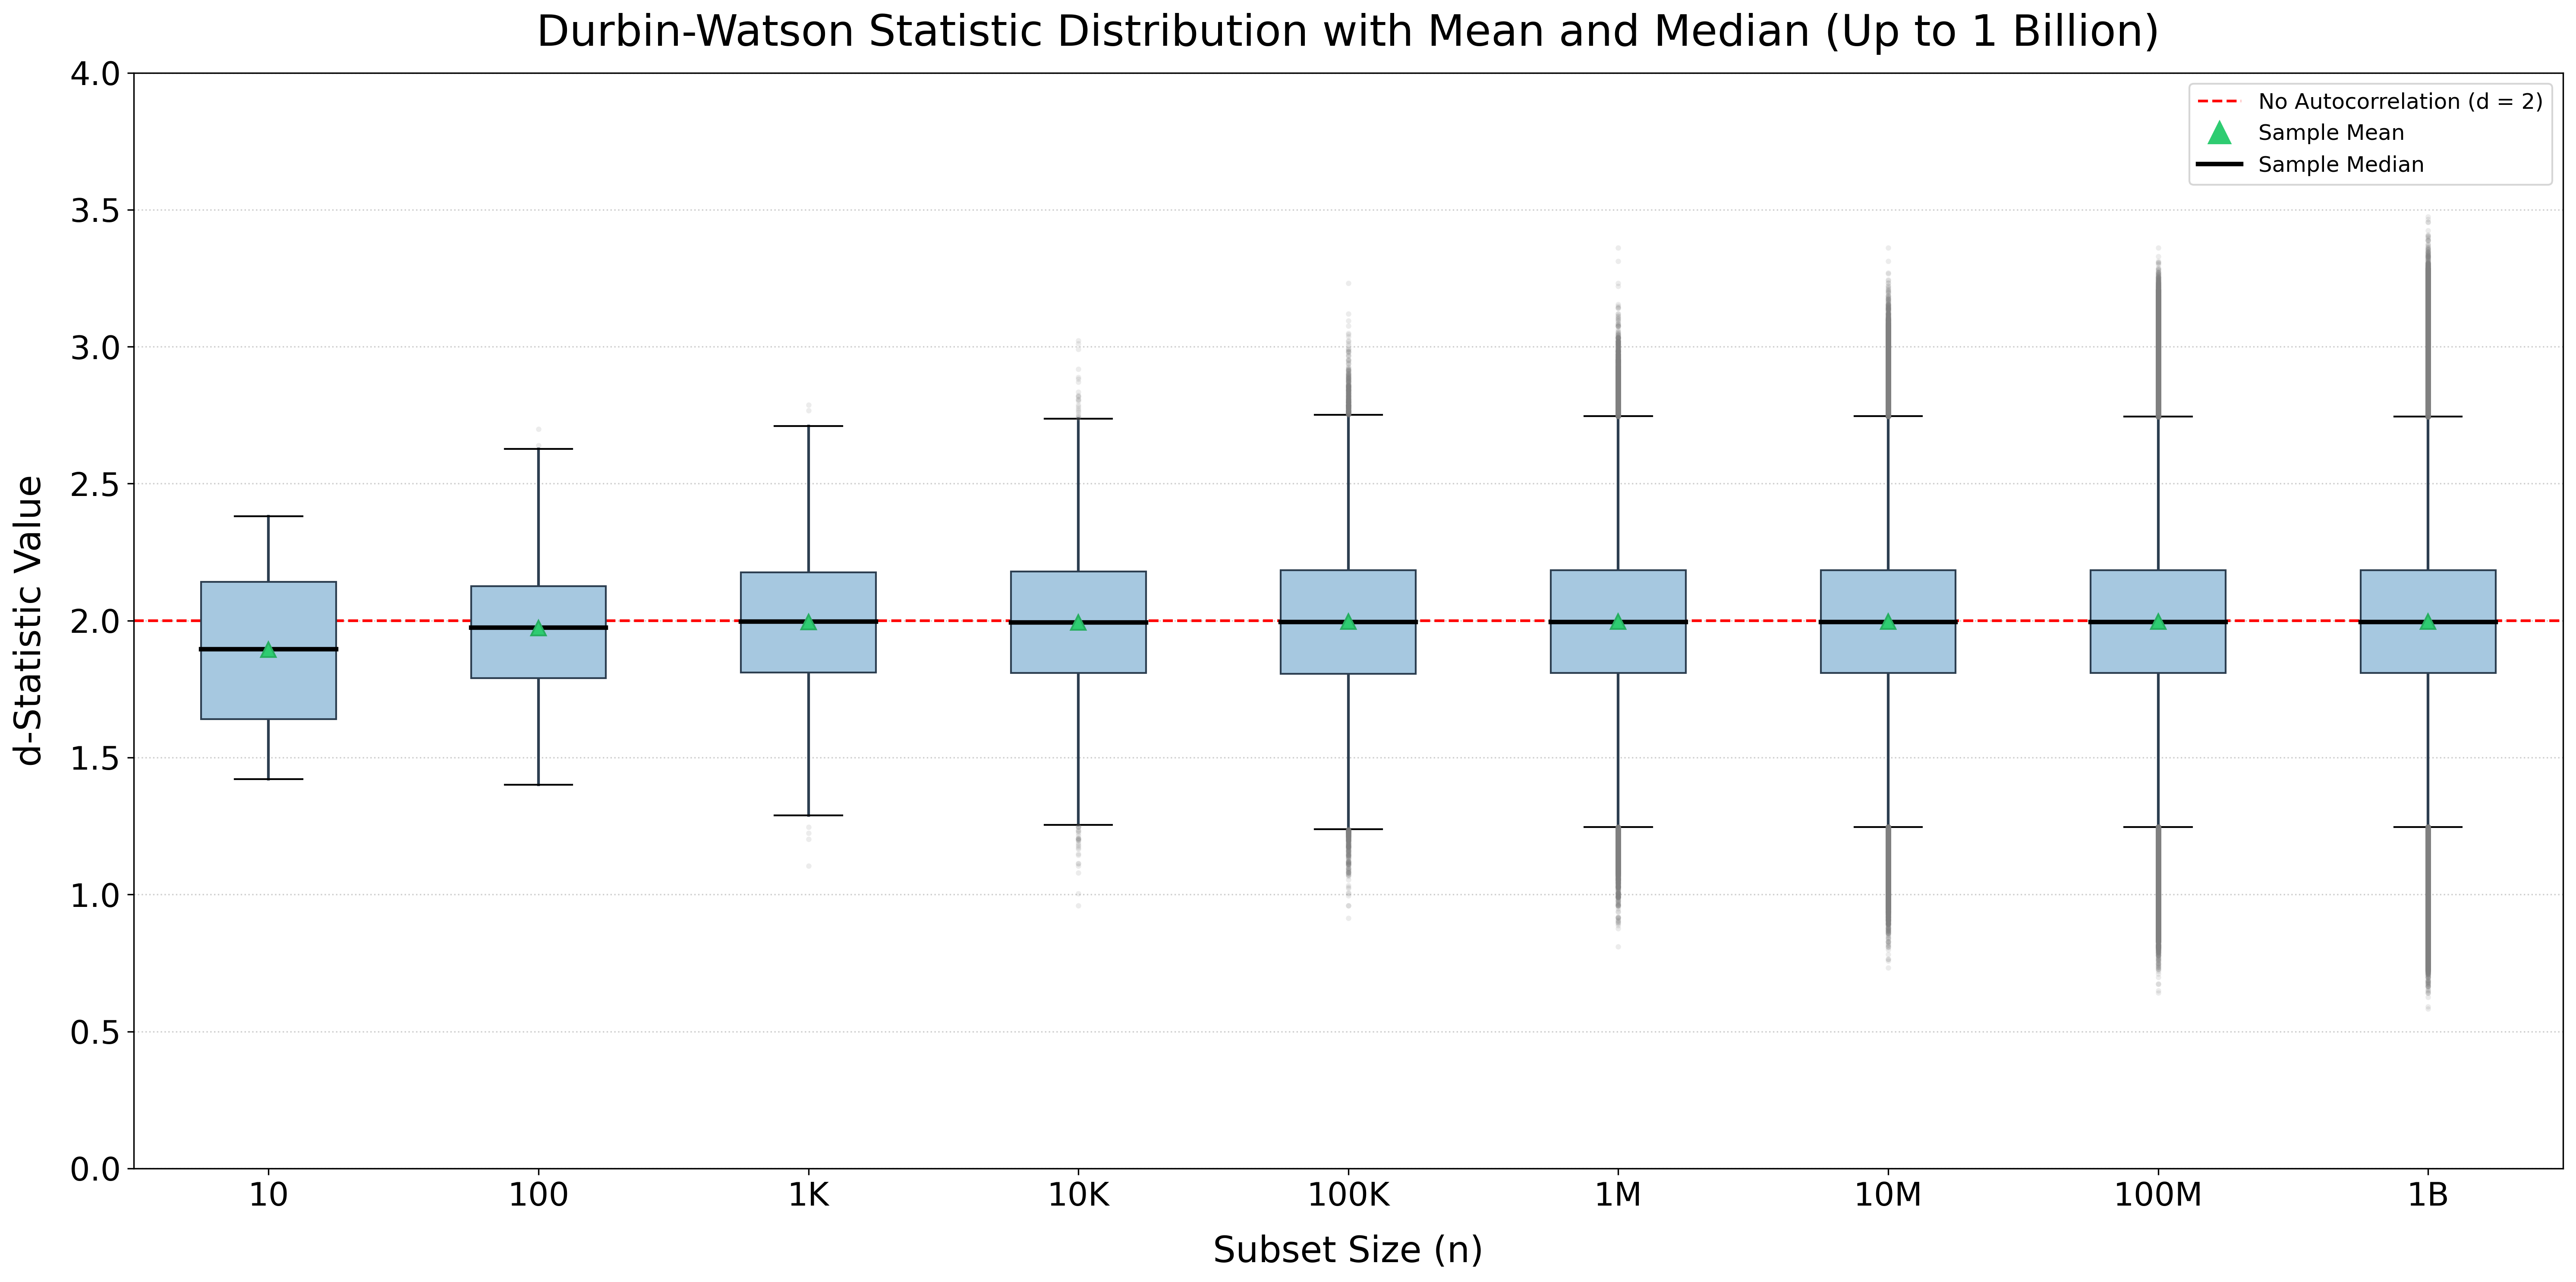

[GLOBAL PROGRESS] [████████████████████████████--] 95% | Phase: Plot Generated and Saved
[GLOBAL PROGRESS] [██████████████████████████████] 100% | Phase: Execution Finished

[TIMER] Total execution time for the cells: 2230.96 seconds (37m 10s)


In [10]:
target_simulations = [10, 100, 1_000, 10_000, 100_000, 1_000_000, 10_000_000, 100_000_000, 1_000_000_000]
metrics = {"Runtime (s)": [], "Mean": [], "Median": [], "Min": [], "Max": [], "Q1": [], "Q3": [], "SD": []}
dw_simulations_history = {}

def calculate_vectorized_dw(permutation_matrix):
    numerator = np.sum(np.diff(permutation_matrix, axis=1) ** 2, axis=1)
    denominator = np.sum(permutation_matrix ** 2, axis=1)
    return numerator / denominator

print(f"Starting massive simulation up to 1 Billion (Sample Seed = {SAMPLE_SEED}, Simulation Seed = {SIMULATION_SEED})...\n")

for idx, n in enumerate(target_simulations):
    cell_start_time = time.time()  # Independent execution counter for this specific subset
    
    # Re-inizializza il generatore con lo stesso SIMULATION_SEED per ogni simulazione
    sim_rng = np.random.default_rng(seed=SIMULATION_SEED)
    
    # Update global bar dynamically based on the current subset size index
    global_pct = 10 + int((idx / len(target_simulations)) * 60)
    print_global_progress(f"Simulation Subsets ({n:,})", global_pct, "yellow")
    
    if n <= 1_000_000:
        indices = sim_rng.random((n, sample_size)).argsort(axis=1)
        dw_values = calculate_vectorized_dw(values[indices])
    else:
        batch_size = set_up_batch_size # or enter a value directly ≤ 10_000_000   
        num_batches = n // batch_size
        dw_values = np.empty(n, dtype=np.float64)
        
        print(f"Processing n = {n:,} in {num_batches} batches:")
        for i in range(num_batches):
            indices = sim_rng.random((batch_size, sample_size)).argsort(axis=1)
            start_idx = i * batch_size
            end_idx = start_idx + batch_size
            dw_values[start_idx:end_idx] = calculate_vectorized_dw(values[indices])
            
            progress = (i + 1) / num_batches
            elapsed = time.time() - cell_start_time
            eta = (elapsed / progress) - elapsed if progress < 1.0 else 0
            eta_str = f"{int(eta // 60)}m {int(eta % 60)}s" if eta > 0 else "0s"
            
            bar = '=' * int(round(20 * progress)) + '-' * (20 - int(round(20 * progress)))
            sys.stdout.write(f"\r[{bar}] {int(progress * 100)}% | Batch {i+1}/{num_batches} | ETA: {eta_str}")
            sys.stdout.flush()
        print()
    
    dw_simulations_history[n] = dw_values.copy()
    
    metrics["Runtime (s)"].append(f"{time.time() - cell_start_time:.1f}")
    metrics["Mean"].append(f"{np.mean(dw_values):.5f}")
    metrics["Median"].append(f"{np.median(dw_values):.5f}")
    metrics["Min"].append(f"{np.min(dw_values):.5f}")
    metrics["Max"].append(f"{np.max(dw_values):.5f}")
    metrics["Q1"].append(f"{np.percentile(dw_values, 25):.5f}")
    metrics["Q3"].append(f"{np.percentile(dw_values, 75):.5f}")
    metrics["SD"].append(f"{np.std(dw_values):.5f}")
    print(f"✓ Successfully processed n = {n:,}\n")

formatted_headers = ["Index"]
for n in target_simulations:
    if n == 1_000_000: formatted_headers.append("1 M")
    elif n == 10_000_000: formatted_headers.append("10 M")
    elif n == 100_000_000: formatted_headers.append("100 M")
    elif n == 1_000_000_000: formatted_headers.append("1 B")
    else: formatted_headers.append(f"{n:,}")

table_rows = []
for metric_name, values_list in metrics.items():
    table_rows.append([metric_name] + values_list)

print(tabulate(table_rows, headers=formatted_headers, tablefmt="simple")) # tablefmt="fancy_grid"

output_filename = "durbin_watson_simulation_results.csv"
try:
    with open(output_filename, mode='w', newline='', encoding='utf-8') as csv_file:
        writer = csv.writer(csv_file)
        writer.writerow(formatted_headers)
        writer.writerows(table_rows)
    print(f"\n[SUCCESS] Matrix data exported to '{output_filename}'")
except IOError as e:
    print(f"\n[ERROR] Failed to write CSV file: {e}")

# Complete Phase 1
print_global_progress("Simulation Completed", 75, "yellow")

# Transition to Green for the visualization phase
print_global_progress("Generating Boxplots (Phase 2/2)", 80, "green")

# Assign variables syntax
dw_simulation_1 = dw_simulations_history[10]
dw_simulation_2 = dw_simulations_history[100]
dw_simulation_3 = dw_simulations_history[1_000]
dw_simulation_4 = dw_simulations_history[10_000]
dw_simulation_5 = dw_simulations_history[100_000]
dw_simulation_6 = dw_simulations_history[1_000_000]
dw_simulation_7 = dw_simulations_history[10_000_000]
dw_simulation_8 = dw_simulations_history[100_000_000]
dw_simulation_9 = dw_simulations_history[1_000_000_000]

data_to_plot = [
    dw_simulation_1, dw_simulation_2, dw_simulation_3,
    dw_simulation_4, dw_simulation_5, dw_simulation_6,
    dw_simulation_7, dw_simulation_8, dw_simulation_9
]

labels = ["10", "100", "1K", "10K", "100K", "1M", "10M", "100M", "1B"]
plt.figure(figsize=(20, 10), dpi=300)

box = plt.boxplot(
    data_to_plot, labels=labels, patch_artist=True, showmeans=True,  
    meanprops=dict(marker='^', markerfacecolor='#2ecc71', markeredgecolor='#27ae60', markersize=8), 
    medianprops=dict(color='#000000', linewidth=2.5), 
    flierprops=dict(marker='o', markerfacecolor='gray', markersize=3, markeredgecolor='none', alpha=0.15)
)

for patch in box['boxes']:
    patch.set_facecolor('#a6c8e0')
    patch.set_edgecolor('#2c3e50')
for whisker in box['whiskers']:
    whisker.set_color('#2c3e50')
    whisker.set_linewidth(1.5)

# Add a horizontal dashed line at d = 2 (No Autocorrelation baseline)
plt.axhline(y=2.0, color='red', linestyle='--', linewidth=1.5, label='No Autocorrelation (d = 2)')

# Custom legend markers to clearly explain Mean vs Median vs Baseline
plt.plot([], [], '^', color='#2ecc71', markersize=12, label='Sample Mean')
plt.plot([], [], color='#000000', linewidth=2.5, label='Sample Median')

# Set plot details, limits, titles, and increased label/tick fonts
plt.ylim(0, 4) 
plt.title("Durbin-Watson Statistic Distribution with Mean and Median (Up to 1 Billion)", fontsize=24, pad=15)

# FONT SIZES FOR AXES TITLES
plt.xlabel("Subset Size (n)", fontsize=20, labelpad=12)
plt.ylabel("d-Statistic Value", fontsize=20, labelpad=12)

# FONT SIZES FOR AXES TICKS (VALUES ON X AND Y)
plt.tick_params(axis='x', labelsize=18)
plt.tick_params(axis='y', labelsize=18)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend(loc='upper right', fontsize=12)

# Save the visualization to disk and display it
output_image_name = "dw_simulation_boxplots.png"
plt.tight_layout()
plt.savefig(output_image_name, dpi=400)
plt.show()

print_global_progress("Plot Generated and Saved", 95, "green")

# Close global status bar at 100%
print_global_progress("Execution Finished", 100, "green")

# --- FINAL TOTAL RUNTIME CALCULATION ---
end_time = time.time()
total_elapsed = end_time - start_time
print(f"\n[TIMER] Total execution time for the cells: {total_elapsed:.2f} seconds ({int(total_elapsed // 60)}m {int(total_elapsed % 60)}s)")